# FrankaTablePush-v0

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/envs/manipulation/frankatablepush_v0.ipynb)

Franka contact pushing on a tabletop.

**isaaclab** · [Environment reference](https://isaac-sim.github.io/IsaacLab/).

A small LeWM baseline experiment: held-out dynamics prediction, a persistence control, and closed-loop planning against random actions. This validates the experiment pipeline; it is not a paper-scale training run.

Run in an Isaac Lab 3.x GPU runtime. This default uses policy state vectors and an MLP encoder, with actual simulator cameras for previews and episodes. Set `observation="rgb"` to train from camera images; the encoder switches to a CNN. `camera="overview"` gives a wider view. The green marker is the target. GT shows that marker for reach, or the object at its target for push/lift; the reference arm pose is not a solved manipulation trajectory.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,benchmark]"

In [1]:
from pathlib import Path

from torch_world.benchmarks import observation_encoder, run_experiment, show_results
from torch_world.envs import FrankaTablePush
from torch_world.models import LeWM
from torch_world.planning import CEM


## Protocol

2,048 requested training pairs; 400 updates; four evaluation seeds; 60-step evaluation budget. Puzzle training and holdout use disjoint starting states. Other tasks use separate collection seeds. Goal-renderable tasks use goal-image MPC; others learn a reward head on frozen embeddings and plan predicted rewards. Actual simulator returns are scored. The one-step model protocol uses `history=1`.

Rendering defaults to high quality: 128-pixel model inputs and 512-pixel presentation frames. Use `quality="low"` or `quality="medium"` to compare cost and quality; `size` and `render_size` can be set independently.

Fixed puzzle layouts use the same start for all four planner seeds. Success intervals therefore describe policy randomness on that level, not generalization across levels.

In [2]:
world = FrankaTablePush(device="cuda:0", quality="high")
SEED, UPDATES = 7, 400
OUTPUT_DIR = Path('../runs/benchmarks/20261015_franka_joint_ranges')

# Replace this factory to compare another WorldModel with the same experiment.
def model_factory(observation_shape, action_dim):
    return LeWM(
        observation_encoder(observation_shape), action_dim, embed_dim=32, history=1,
        depth=2, num_heads=4, head_dim=8, mlp_dim=64, proj_dim=64, dropout=0,
    )


def planner_factory(action_dim):
    return CEM(8, action_dim, num_samples=96, num_elites=12, iterations=3, bounds=(-1, 1))


Seed not set for the environment. The environment creation may not be deterministic.


[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : None
	Physics step-size     : 0.008333333333333333
	Rendering step-size   : 0.03333333333333333
	Environment step-size : 0.03333333333333333


I: Initializing Version 2.72.3-release.7151+gl.5390bed9
I: Client ID: T4XH2DX3
I: Not using Hub: Hub not found
I: Successfully created S3 provider for https://omniverse-content-production.s3-us-west-2.amazonaws.com


I: Using CloudFront http://dcb18d6mfegct.cloudfront.net/, List = No
Serving remote assets from the local cache under '/tmp'. Each copy is checked against the server before use; delete the directory to force a full re-download.


/clusterhome/kleyton/xevals-isaaclab-validation/IsaacLab/source/isaaclab_newton/isaaclab_newton/cloner/replicate.py:132: FutureWarning: Newton shape color replacement is enabled; this workaround will be deprecated in a future release.
  replace_newton_builder_shape_colors(builder, stage)


...

[INFO]: Time taken for scene creation Last: 1.573627 s, Mean: 1.573627 s, Std: 0.000000 s, N: 1
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 1
	Environment spacing   : 2.5
	Source prim name      : /World/envs/env_0
	Global prim paths     : []
	Replicate physics     : True


Failed to get root com velocity. If the articulation is fixed, this is expected. Setting root com velocity to zeros.


Finalize builder took: Last: 3.419905 s, Mean: 3.419905 s, Std: 0.000000 s, N: 1


Initialize solver took: Last: 1.492304 s, Mean: 1.492304 s, Std: 0.000000 s, N: 1


CUDA graph took: Last: 1.655442 s, Mean: 1.655442 s, Std: 0.000000 s, N: 1
[INFO]: Time taken for simulation start Last: 6.975710 s, Mean: 6.975710 s, Std: 0.000000 s, N: 1
[INFO] Command Manager:  <CommandManager> contains 0 active terms.
+----------------------+
| Active Command Terms |
+-------+------+-------+
| Index | Name |  Type |
+-------+------+-------+
+-------+------+-------+

[INFO] Event Manager:  <EventManager> contains 1 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+------------------+------------------+
|      Index       | Name             |
+------------------+------------------+
|        0         | reset            |
+------------------+------------------+

[INFO] Recorder Manager:  <RecorderManager> contains 0 active terms.
+-----------------------+
| Active Recorder Terms |
+------------+----------+
|   Index    | Name     |
+------------+----------+
+------------+----------+

[INFO] Action Manager:  <ActionManager>

**FrankaTablePush-v0 · isaaclab** — Franka contact pushing on a tabletop. 9 normalized action components in [-1, 1].

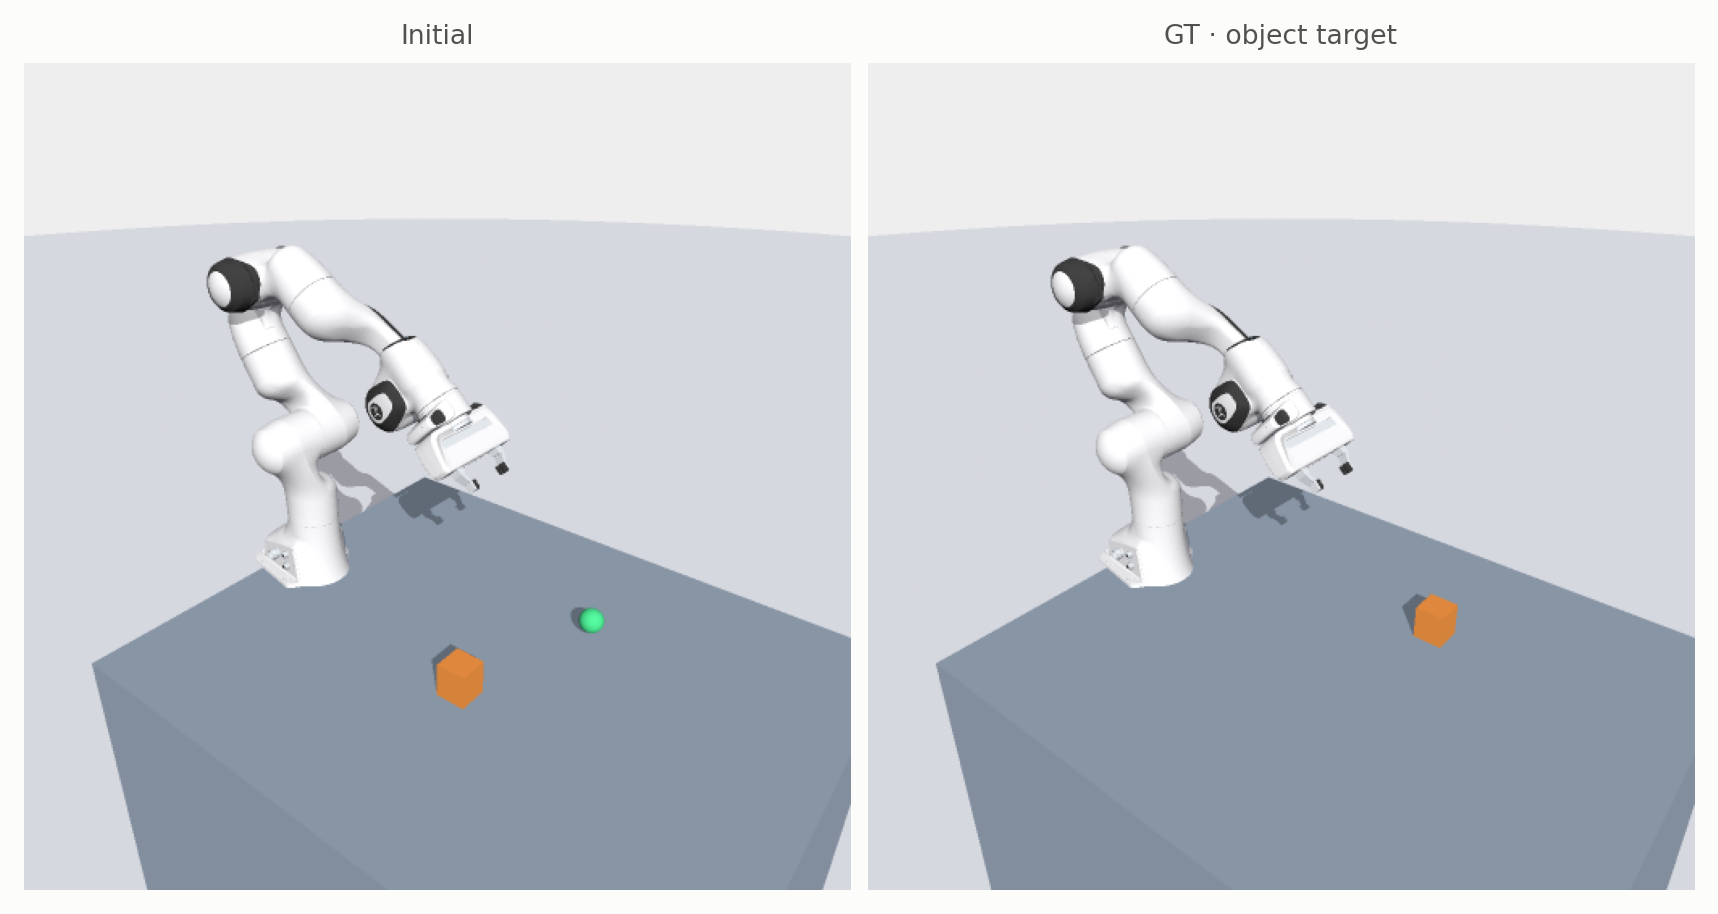

In [3]:
world.show_env()


In [4]:
result = run_experiment(
    world, model_factory=model_factory, planner_factory=planner_factory,
    seed=SEED, updates=UPDATES, output_dir=OUTPUT_DIR,
)


## GT reference

A verified successful episode GIF with persistent GT, separate from measured model results. Reference controllers may use a longer episode budget; the GIF shows actual simulator steps.

**FrankaTablePush-v0** — verified reference episode · 381 simulator steps; separate from model evaluation.

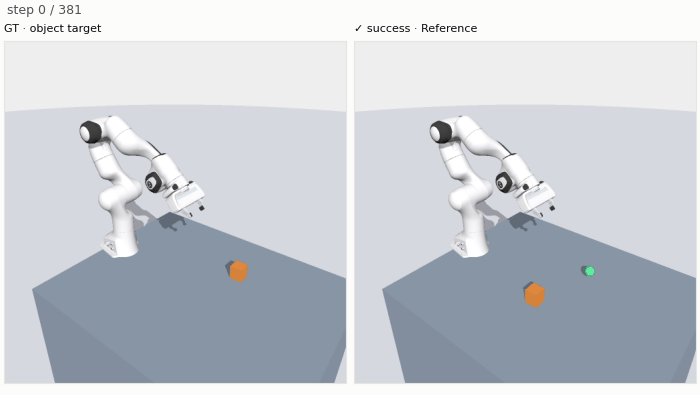

Static preview of the recorded episode. Rerun this cell to view the animation.

In [5]:
world.show_success()


## Results

Lower prediction error alone does not establish planning competence.

**FrankaTablePush-v0 · LeWM** — state observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 171.4 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 0.2588 |
| Persistence | 0.3228 |

Latent standard deviation: **0.821**. Latent errors are comparable within this model; their scale differs between models.

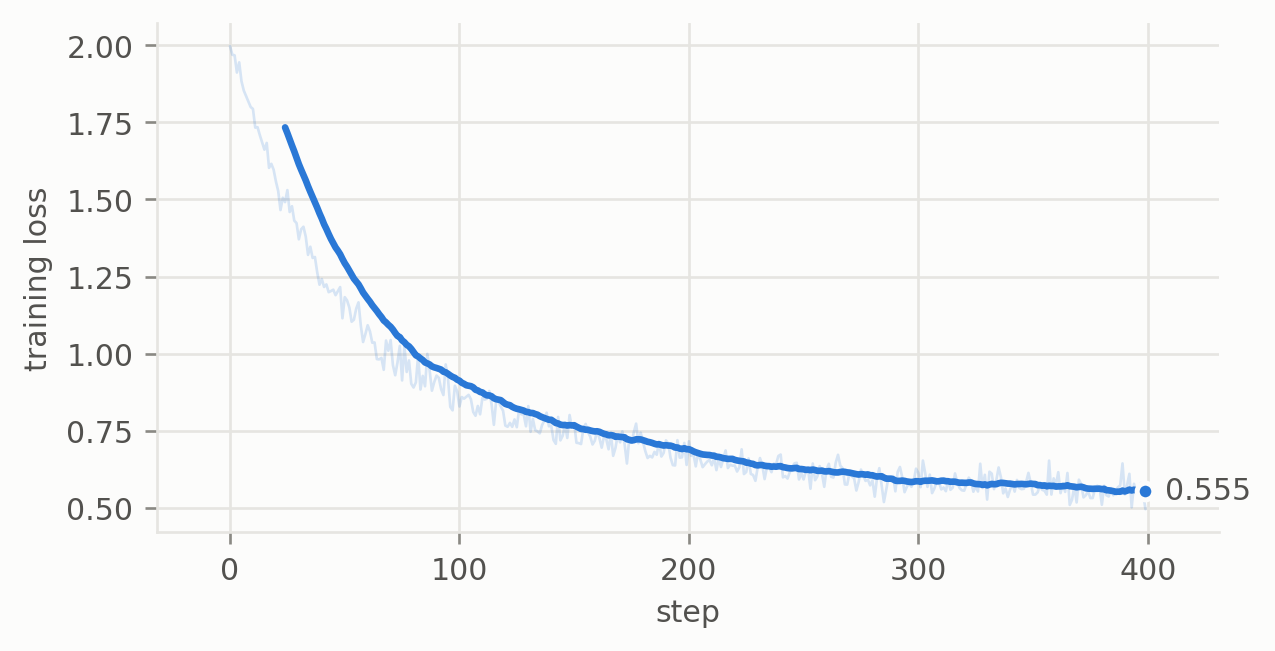

| Policy | Success | Steps | Return ↑ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 49%] | 60.0 | -0.635 |
| random | 0% [0%, 49%] | 60.0 | -0.638 |

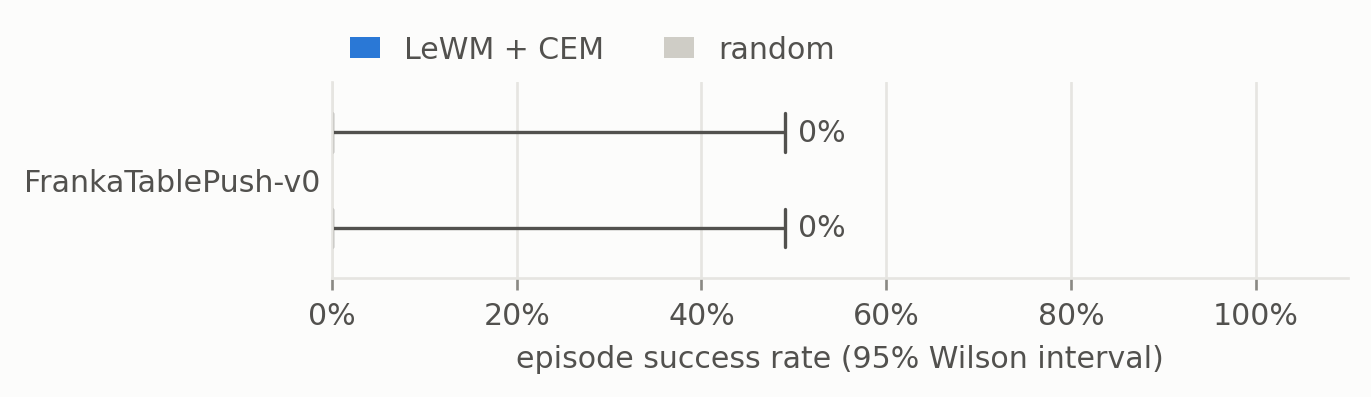

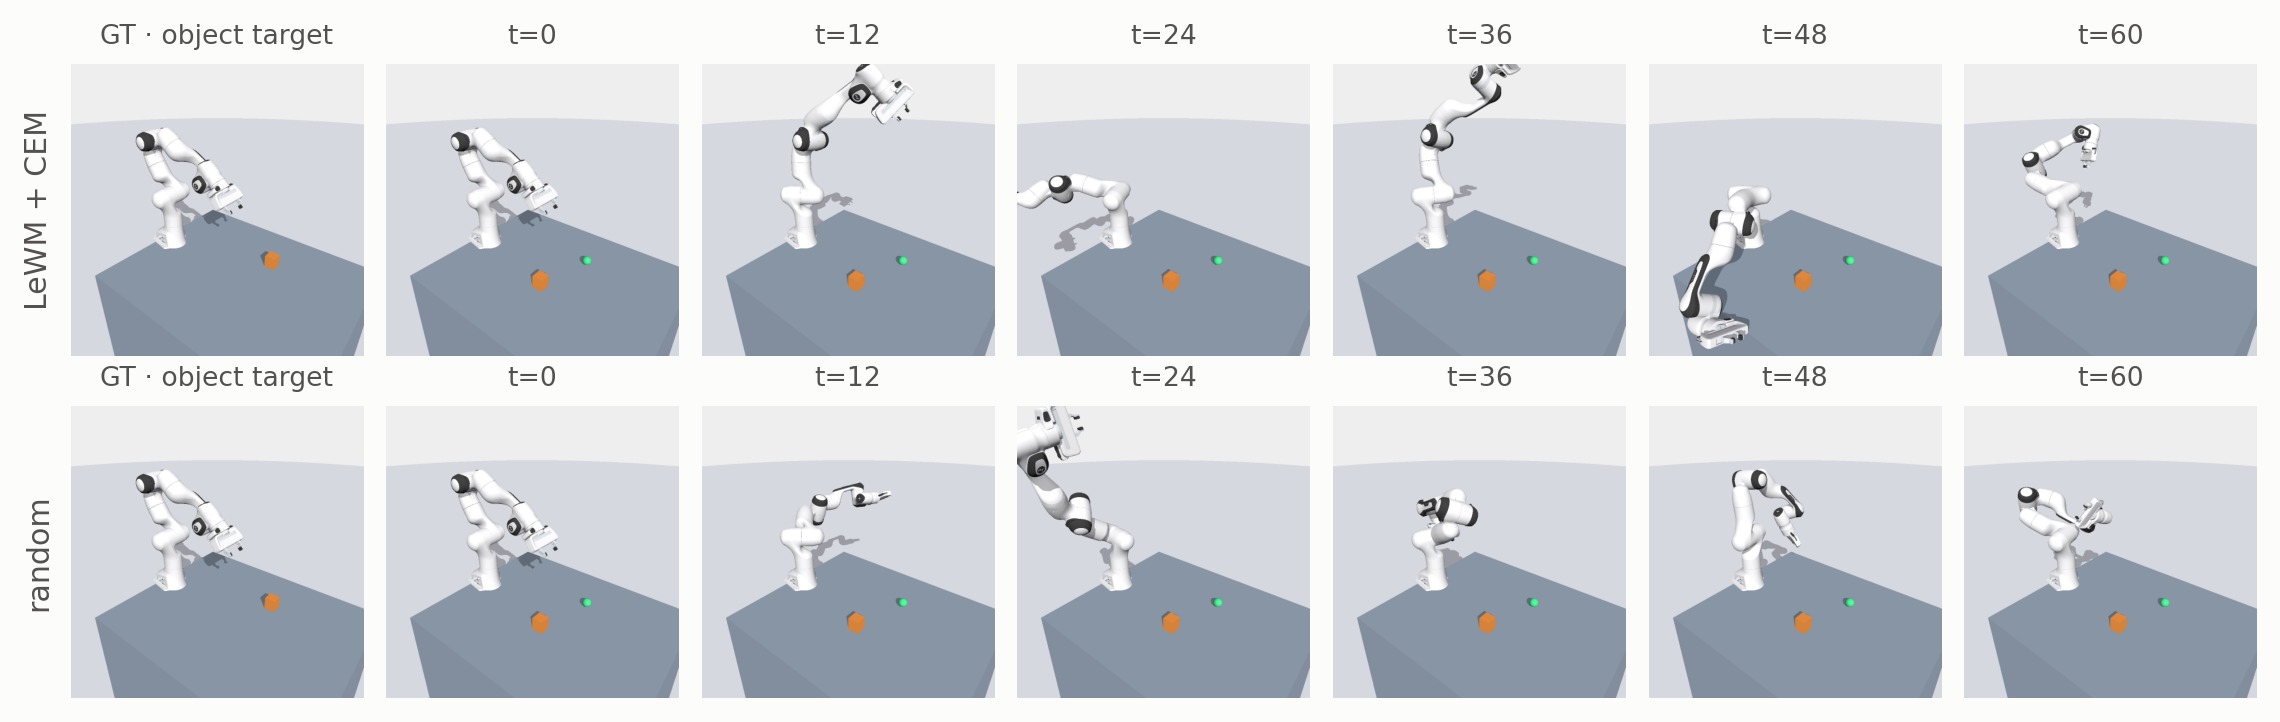

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

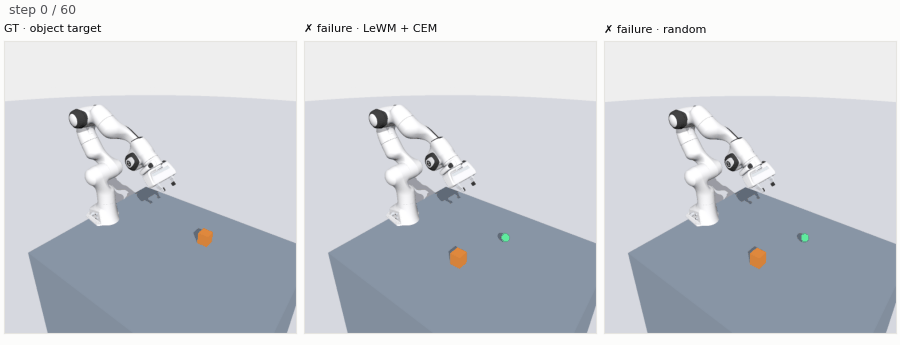

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/benchmarks/20261015_franka_joint_ranges/FrankaTablePush-v0/LeWM/20261015T143311791637Z-e3afb0e7


In [6]:
show_results(result)
print("Saved run:", result["run_dir"])


In [7]:
world.close()
